Loaded Dataset Shape: (7043, 21)
Using SMOTE for Random Forest class balancing...
Using XGBoost Classifier...

          CHURN MODEL BENCHMARK REPORT            
Random Forest ROC-AUC Score     : 0.8267
Gradient Boosting ROC-AUC Score : 0.8374

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.87      0.79      0.83      1033
           1       0.54      0.68      0.60       374

    accuracy                           0.76      1407
   macro avg       0.71      0.74      0.72      1407
weighted avg       0.79      0.76      0.77      1407

--- Gradient Boosting Classification Report ---
              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1033
           1       0.51      0.80      0.62       374

    accuracy                           0.74      1407
   macro avg       0.71      0.76      0.71      1407
weighted avg       0.80      0.74      0.76      1407



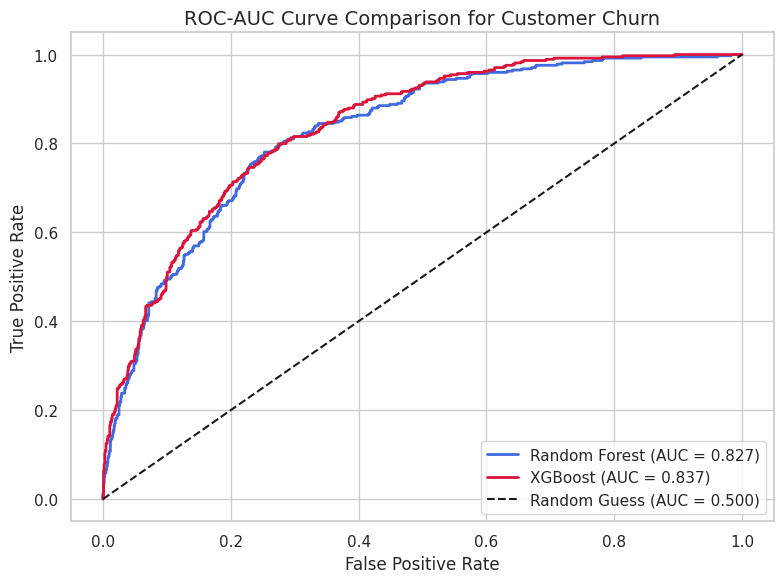


Top 10 Most Influential Feature Importances (Random Forest):
                       Feature  Importance
       Contract_Month-to-month    0.124466
                        tenure    0.094734
             OnlineSecurity_No    0.084649
PaymentMethod_Electronic check    0.064875
                TechSupport_No    0.063797
                  TotalCharges    0.063161
             Contract_Two year    0.058177
                MonthlyCharges    0.046246
   InternetService_Fiber optic    0.035644
            OnlineSecurity_Yes    0.028968


/tmp/ipykernel_1471/3192594349.py:178: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')


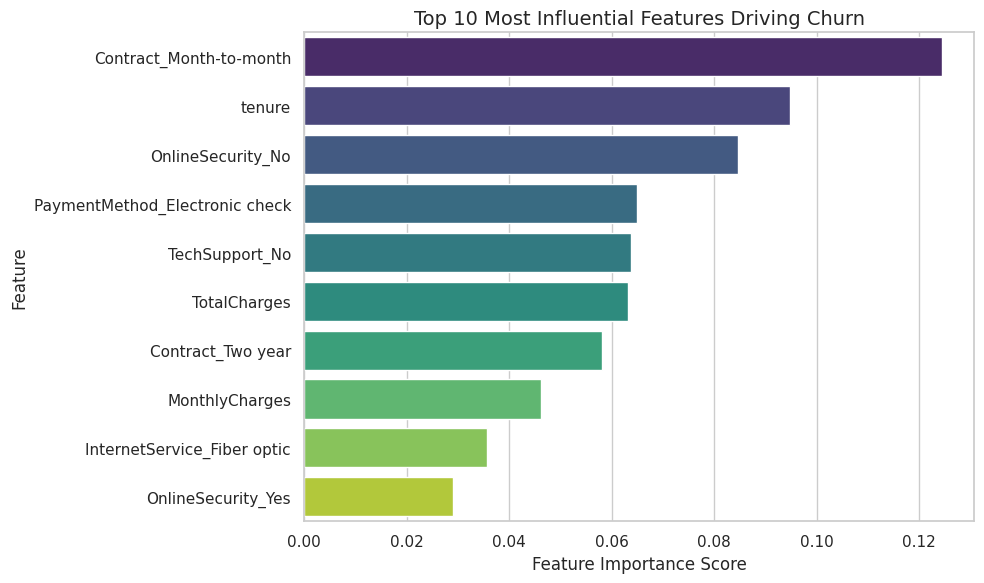

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report

# Try importing SMOTE and XGBoost if installed, otherwise fallback to Scikit-Learn equivalents
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
    HAS_SMOTE = True
except ImportError:
    HAS_SMOTE = False

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

# Set visual style
sns.set_theme(style="whitegrid")

def run_churn_prediction_pipeline(data_source):
    # 1. Load Dataset (Accepts DataFrame or file path string)
    if isinstance(data_source, str):
        df = pd.read_csv(data_source)
    else:
        df = data_source.copy()

    print(f"Loaded Dataset Shape: {df.shape}")

    # 2. Data Preprocessing & Cleaning
    # Convert TotalCharges to numeric (handles blanks/spaces safely)
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    df = df.dropna(subset=['TotalCharges'])

    # Drop identifier column if present
    if 'customerID' in df.columns:
        df = df.drop(columns=['customerID'])

    # Map target variable 'Churn' to binary (1 = Yes, 0 = No)
    if df['Churn'].dtype == 'object':
        df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

    X = df.drop(columns=['Churn'])
    y = df['Churn']

    # 3. Train/Test Stratified Split (80/20)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )

    categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
    numerical_cols = X.select_dtypes(include=['number']).columns.tolist()

    # 4. Feature Pipeline Setup (Imputation + Scaling + OneHotEncoding)
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]), numerical_cols),
            ('cat', Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
            ]), categorical_cols)
        ]
    )

    # 5. Define Ensemble Models & Handle Class Imbalance
    if HAS_SMOTE:
        print("Using SMOTE for Random Forest class balancing...")
        rf_pipeline = ImbPipeline(steps=[
            ('preprocessor', preprocessor),
            ('smote', SMOTE(random_state=42)),
            ('classifier', RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42))
        ])
    else:
        print("Using class_weight='balanced' for Random Forest...")
        rf_pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', RandomForestClassifier(
                n_estimators=150, max_depth=10, class_weight='balanced', random_state=42
            ))
        ])

    neg_count = (y_train == 0).sum()
    pos_count = (y_train == 1).sum()
    scale_weight = neg_count / pos_count if pos_count > 0 else 1.0

    if HAS_XGB:
        print("Using XGBoost Classifier...")
        boost_classifier = XGBClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=5,
            scale_pos_weight=scale_weight,
            random_state=42,
            eval_metric='logloss'
        )
    else:
        print("Using Scikit-Learn GradientBoostingClassifier...")
        boost_classifier = GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=4,
            random_state=42
        )

    boost_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', boost_classifier)
    ])

    # Fit Models
    rf_pipeline.fit(X_train, y_train)
    boost_pipeline.fit(X_train, y_train)

    # 6. Model Evaluation (ROC-AUC)
    y_pred_rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]
    y_pred_boost_prob = boost_pipeline.predict_proba(X_test)[:, 1]

    auc_rf = roc_auc_score(y_test, y_pred_rf_prob)
    auc_boost = roc_auc_score(y_test, y_pred_boost_prob)

    print("\n==================================================")
    print("          CHURN MODEL BENCHMARK REPORT            ")
    print("==================================================")
    print(f"Random Forest ROC-AUC Score     : {auc_rf:.4f}")
    print(f"Gradient Boosting ROC-AUC Score : {auc_boost:.4f}")
    print("==================================================\n")

    print("--- Random Forest Classification Report ---")
    print(classification_report(y_test, rf_pipeline.predict(X_test)))

    print("--- Gradient Boosting Classification Report ---")
    print(classification_report(y_test, boost_pipeline.predict(X_test)))

    # 7. Plot ROC-AUC Curves
    plt.figure(figsize=(8, 6))
    fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_rf_prob)
    fpr_boost, tpr_boost, _ = roc_curve(y_test, y_pred_boost_prob)

    plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})", color='royalblue', lw=2)
    boost_label = "XGBoost" if HAS_XGB else "Gradient Boosting"
    plt.plot(fpr_boost, tpr_boost, label=f"{boost_label} (AUC = {auc_boost:.3f})", color='crimson', lw=2)
    plt.plot([0, 1], [0, 1], 'k--', label="Random Guess (AUC = 0.500)")
    plt.xlabel("False Positive Rate", fontsize=12)
    plt.ylabel("True Positive Rate", fontsize=12)
    plt.title("ROC-AUC Curve Comparison for Customer Churn", fontsize=14)
    plt.legend(loc="lower right", fontsize=11)
    plt.tight_layout()
    plt.show()

    # 8. Top 10 Most Influential Feature Importances
    cat_encoder = rf_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
    encoded_cat_cols = cat_encoder.get_feature_names_out(categorical_cols).tolist()
    all_feature_names = numerical_cols + encoded_cat_cols

    rf_importances = rf_pipeline.named_steps['classifier'].feature_importances_
    feature_importance_df = pd.DataFrame({
        'Feature': all_feature_names,
        'Importance': rf_importances
    }).sort_values(by='Importance', ascending=False)

    print("\nTop 10 Most Influential Feature Importances (Random Forest):")
    print(feature_importance_df.head(10).to_string(index=False))

    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')
    plt.title("Top 10 Most Influential Features Driving Churn", fontsize=14)
    plt.xlabel("Feature Importance Score", fontsize=12)
    plt.ylabel("Feature", fontsize=12)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    # Specify your CSV filename or dataset URL here
    url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
    run_churn_prediction_pipeline(url)